# Time Series Interview Questions — the Round with Its Own Rules

Time-series rounds are short-circuit tests: one question — "how do you validate?" — separates people who've thought about temporal ordering from people who haven't. If you say "train_test_split with shuffle" here, the round is over. Below: stationarity tested for real, ARIMA by the book, and the leak-free split that makes every number honest.

## Q1 — The Components, and the Mistake Each One Causes

A series decomposes into **trend** (long-run direction), **seasonality** (fixed-period cycles), and **residual** (everything else). Interviewers probe the mistakes: treating **multiplicative** seasonality as additive (amplitude growing with level — log-transform first); confusing **seasonal** (fixed period, yearly) with **cyclical** (irregular period, business cycles); and forecasting the *trend-extrapolated* level when the business question was about the *change*. Always state: *"I decompose first, because each component is handled by a different mechanism."*

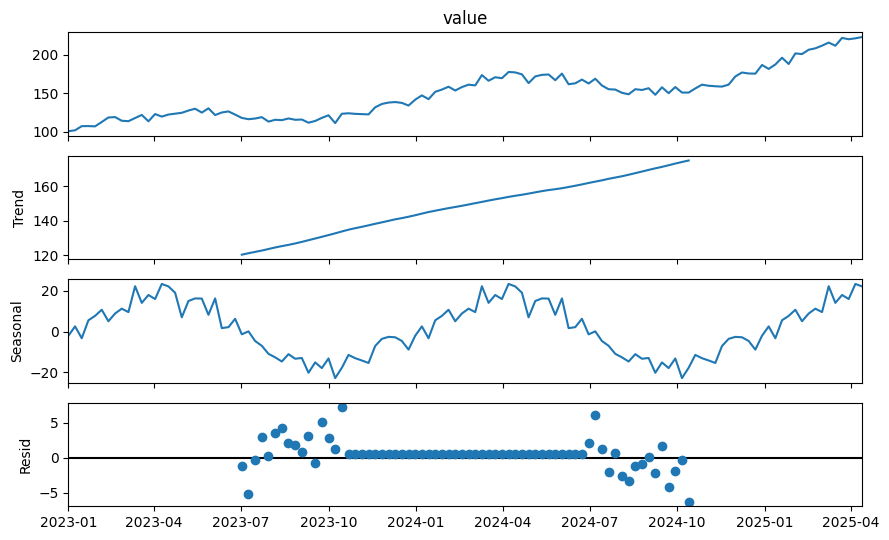

trend up, seasonal flat-ish, residual structureless — additive worked here
if seasonal amplitude tracked the level, I'd log-transform and use multiplicative


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

idx = pd.date_range("2023-01-01", periods=120, freq="W")
t = np.arange(120)
rng = np.random.default_rng(0)
level = 100 + 0.8 * t
season = 12 * np.sin(2 * np.pi * t / 52) * (1 + t / 120)   # growing amplitude: multiplicative-flavored
series = pd.Series(level + season + rng.normal(0, 4, 120), index=idx, name="value")

dec = seasonal_decompose(series, model="additive", period=52)
fig = dec.plot(); fig.set_size_inches(9, 5.5); fig.tight_layout()
plt.show()
print("trend up, seasonal flat-ish, residual structureless — additive worked here")
print("if seasonal amplitude tracked the level, I'd log-transform and use multiplicative")

## Q2 — Stationarity: What, Why, How to Test, How to Fix

**Stationary** = statistical properties (mean, variance, autocorrelation) constant over time. Classical models (ARMA, and ARIMA on the differenced series) *assume* it. **Tests:** ADF (H₀ = unit root = non-stationary; p < 0.05 → stationary) and KPSS (H₀ reversed = stationary — the two together make a robust 2×2). **Fixes, in escalation order:** log/Box-Cox (stabilizes variance), differencing d times (fixes trend), seasonal differencing D for seasonal unit roots. The auto-answer when asked *"how do you know d?"*: differencing until ADF rejects, and as few times as possible — over-differencing injects artificial negative autocorrelation.

In [2]:
from statsmodels.tsa.stattools import adfuller, kpss

prices = pd.Series(100 + 0.9 * np.cumsum(rng.normal(0, 1, 300)) + 0.1 * np.arange(300),
                   index=pd.date_range("2020-01-01", periods=300, freq="D"), name="price")

def report(series, name):
    adf_p = adfuller(series.dropna(), autolag="AIC")[1]
    kpss_p = kpss(series.dropna(), regression="c", nlags="auto")[1]
    verdict = "stationary" if adf_p < 0.05 and kpss_p > 0.05 else "NON-stationary"
    print(f"{name:>18}: ADF p={adf_p:.3f}, KPSS p={kpss_p:.3f} -> {verdict}")

report(prices, "price (raw)")
report(prices.diff(), "first difference")
report(prices.diff().diff(), "second difference")
print("d=1 is enough — a second difference would start over-differencing")

       price (raw): ADF p=0.055, KPSS p=0.026 -> NON-stationary
  first difference: ADF p=0.000, KPSS p=0.100 -> stationary
 second difference: ADF p=0.000, KPSS p=0.100 -> stationary
d=1 is enough — a second difference would start over-differencing


/tmp/ipykernel_2452/1625586501.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(series.dropna(), autolag="AIC")[1]
/tmp/ipykernel_2452/1625586501.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_p = kpss(series.dropna(), regression="c", nlags="auto")[1]
/tmp/ipykernel_2452/1625586501.py:7: FutureWarning: a

## Q3 — ARIMA: the (p, d, q) You Can Actually Justify

**AR(p)** — value regresses on its own p lags (momentum). **I(q)** — regression on q lagged *forecast errors* (shock correction). **d** — differencing count. **SARIMA** adds (P, D, Q, s) for the seasonal side. **Order selection, the defensible recipe:** fix d by ADF (above); read **ACF/PACF** (cutoff after q in ACF → MA(q); cutoff after p in PACF → AR(p)); refine by AIC/BIC over a small grid; validate out-of-sample with the rolling split (Q5). The pragmatic point to volunteer: *ARIMA is the interpretable baseline, not the default winner — ETS and GBM-on-lags are serious competitors.*

/home/z/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


selected order (2, 0, 2) by AIC=496.7
out-of-sample RMSE: 0.589 (series std 0.923)


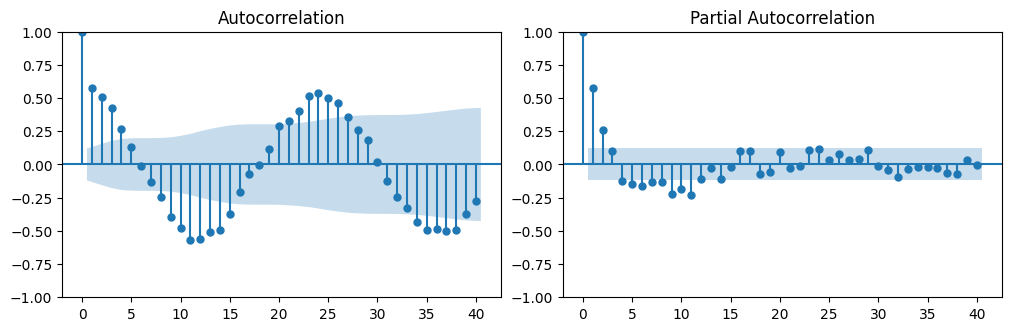

ACF/PACF oscillating at lag 24 = the hourly seasonality — a seasonal order would capture it


In [3]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

y = pd.Series(np.sin(2*np.pi*np.arange(300)/24) + rng.normal(0, 0.6, 300),
              index=pd.date_range("2020-01-01", periods=300, freq="h"), name="y")

train, test = y.iloc[:264], y.iloc[264:]
best = None
for p in range(3):
    for q in range(3):
        try:
            m = ARIMA(train, order=(p, 0, q)).fit()
            if best is None or m.aic < best[0].aic:
                best = (m, (p, 0, q))
        except Exception:
            pass
m, order = best
print(f"selected order {order} by AIC={m.aic:.1f}")

forecast = m.get_forecast(len(test))
pred = forecast.predicted_mean
rmse = float(np.sqrt(np.mean((test.values - pred.values) ** 2)))
print(f"out-of-sample RMSE: {rmse:.3f} (series std {y.std():.3f})")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), constrained_layout=True)
plot_acf(train, lags=40, ax=axes[0]); plot_pacf(train, lags=40, ax=axes[1], method="ywm")
plt.show()
print("ACF/PACF oscillating at lag 24 = the hourly seasonality — a seasonal order would capture it")

## Q4 — Exponential Smoothing in One Breath Each

**SES** (simple) — exponentially decaying weighted average, one parameter α, for flat series. **Holt** — SES + trend term. **Holt-Winters** — + seasonality, additive or multiplicative. The family's virtue: interpretable, fast, hard to beat on clean seasonal data; statsmodels calls it `ETSModel`. Say: *"exponential smoothing and ARIMA are the two classical bookends; both belong in the baseline set."*

## Q5 — Validation: the Split That Doesn't Lie

The answer that decides the round: **never shuffle, never random k-fold.** The menu, best to acceptable:

1. **Rolling-origin (walk-forward) CV** — expanding or sliding train window, forecast the next h, roll forward, average errors across origins. The gold standard; mimics production exactly.
2. **Single holdout with a temporal cut** — cheap, one number, fine for a quick take-home.
3. **Multiple cutoffs** — quarterly splits for seasonal robustness.

**Also say the horizon rule:** evaluate exactly at the horizons the business consumes (1-day vs 1-month errors are different products), and **never** let lag features computed from the future touch training rows — `shift(1)` before any rolling stat.

In [4]:
def rolling_origin_rmse(y, n_origins=6, horizon=12, order=(2, 0, 1)):
    rmses = []
    for k in range(n_origins):
        cut = len(y) - horizon * (k + 1)
        tr, te = y.iloc[:cut], y.iloc[cut:cut + horizon]
        m = ARIMA(tr, order=order).fit()
        pred = m.get_forecast(len(te)).predicted_mean
        rmses.append(np.sqrt(np.mean((te.values - pred.values) ** 2)))
    return np.array(rmses)

rmses = rolling_origin_rmse(y)
print("rolling-origin RMSE per fold:", rmses.round(3))
print(f"mean +/- std: {rmses.mean():.3f} +/- {rmses.std():.3f}")
print("multiple origins = error across different regimes — the honest number")

rolling-origin RMSE per fold: [0.935 1.105 0.966 0.987 1.044 0.716]
mean +/- std: 0.959 +/- 0.122
multiple origins = error across different regimes — the honest number


## Q6 — Forecasting Metrics: Scale-Aware and Scale-Free

**MAE/RMSE** — target units, RMSE punishing big misses. **MAPE** — the trap: undefined at zero, explodes near zero, asymmetric in over- vs under-forecasts; fine for positive series only. **sMAPE/MASE** — the fixed versions: MASE divides MAE by the in-sample naive error, so **MASE < 1 means "beats the naive forecast"** — the interpretation interviewers love. Always keep the **naive baseline** (last value, or last value + last seasonal delta): any model that can't beat it is complexity with no return.

In [5]:
naive = np.roll(test.values, 1); naive[0] = train.iloc[-1]   # last-value forecast
naive_rmse = np.sqrt(np.mean((test.values - naive) ** 2))
ratio = rmse / naive_rmse
print(f"ARIMA RMSE     : {rmse:.3f}")
print(f"naive RMSE     : {naive_rmse:.3f}")
print(f"ratio (MASE-spirit): {ratio:.2f}  -> {'beats' if ratio < 1 else 'does NOT beat'} the naive baseline")

ARIMA RMSE     : 0.589
naive RMSE     : 0.830
ratio (MASE-spirit): 0.71  -> beats the naive baseline


## Q7 — Feature-Based Forecasting: the Modern Tabular Answer

*“You have gradient-boosted trees — how do you forecast?”* Convert forecasting into supervised learning: **lags** (yₜ₋₁, yₜ₋₂, ...), **rolling stats** (mean/std of the past 7/28 — shifted!), **calendar features** (dow, month, holiday), then LightGBM/CatBoost on top. Strengths: exogenous features first-class, **global models** (one model for all stores, store-id as feature), nonlinear effects. Weaknesses: no native uncertainty, horizon handling (recursive vs direct), cold-start. The 2026 honest stack: *classical (ETS/ARIMA) + global GBM + optionally deep (N-BEATS/TFT family) — ensemble them.* The repo's Level-4 [Time Series notebook](../../4.%20Diving%20into%20different%20domains/Time%20Series/Time%20Series.ipynb) executes the full classical pipeline.

In [6]:
df = pd.DataFrame({"y": y})
for lag in (1, 2, 3, 24):
    df[f"lag_{lag}"] = df["y"].shift(lag)
df["roll24_mean"] = df["y"].shift(1).rolling(24).mean()
df["hour"] = df.index.hour
df = df.dropna()

X = df.drop(columns="y"); target = df["y"]
from lightgbm import LGBMRegressor
gb = LGBMRegressor(n_estimators=300, verbose=-1).fit(X.iloc[:-36], target.iloc[:-36])
pred_gb = gb.predict(X.iloc[-36:])
rmse_gb = float(np.sqrt(np.mean((target.iloc[-36:].values - pred_gb) ** 2)))
print(f"LightGBM-on-lags RMSE (last 36h): {rmse_gb:.3f} vs series std {target.std():.3f}")
print("lags + calendar features turned forecasting into ordinary supervised learning")

LightGBM-on-lags RMSE (last 36h): 0.724 vs series std 0.919
lags + calendar features turned forecasting into ordinary supervised learning


## Q8 — Quick-Fire Time Series Round

| Question | The 15-second answer |
| --- | --- |
| White noise vs random walk? | White noise: iid, zero autocorrelation; random walk: the *differences* are white noise — level wanders; forecasting a walk = repeat last value |
| ADF null hypothesis? | Unit root (non-stationary); p<0.05 → reject → stationary. KPSS is the mirror test — run both |
| Granger causality? | X "Granger-causes" Y if X's lags improve Y's forecasts; prediction-relationship, NOT causal mechanism — always add the caveat |
| Recursive vs direct multi-step? | Recursive: one model, feed predictions back (errors compound); direct: one model per horizon (more models, no compounding) |
| Structural break? | A regime change (policy, launch); detect (CUSUM) or model explicitly; rolling windows limit the damage |
| Prophet — when? | Strong seasonal + holiday effects, missing data, interpretable components; robustness and explainability leader, not accuracy leader |
| Detecting seasonality programmatically? | ACF peaks at lag s, periodogram peaks, or STL strength-of-seasonality |
| Forecast uncertainty? | Prediction intervals (analytic for ARIMA), conformal prediction for any model — the modern distribution-free answer |